# Emanuel's tests on the North Atlantic

Emanuel (2025) proposes a set of metrics, each made of counts, and four skill tests that score a
synthetic set against observations: the Poisson deviance (D′), the K-test (K′), the coefficient of
determination (r²) and χ² (χ²′), each 1 for a perfect match. John et al. (2026) apply six of the
metrics, all in the North Atlantic, to CHAZ, the MIT model and RAFT, together with the ratio of US
landfalls to basin storms over the observed ratio (Rk′). `ocr.risks.hurricane.skill` implements
the tests and `ocr.risks.hurricane.report` the metrics. This notebook checks the implementation
against John et al.'s published scores and then scores our runs and the CHAZ team's set.

The tests are a check against published practice. We do not use them to choose between our setups
([intensity.ipynb](intensity.ipynb), section 5, compares those). The setups (the public code's
settings, called 'shipped', and the refit options described there) share seeds and tracks, and
every metric here scales the overall storm count away, so their scores differ through intensity:
which members reach 40 kt and when, how strong they get, and which still carry a wind when their
track reaches the coast.

A storm counts if its lifetime maximum reaches 40 kt and it first reaches 40 kt in the North
Atlantic; for CHAZ, each intensity member counts as a storm. Where the papers leave a choice open we read them as
the `report` module describes and test the alternatives in section 1:

- intensity histograms count storms at or above each 5 kt step from 40 kt, over the period; the
  synthetic counts are scaled either to the observed total or to 12 storms a year (Emanuel's
  Table 2) and 3 US landfalls a year (John et al., section 3)
- the 6-hour intensity change is a histogram of every 6-hour step, accumulated from each tail
  towards its peak bin. Emanuel's Figure 6b caption describes the accumulation as starting at the
  peak; we read it as two-sided cumulative counts that fall away from the peak. The tests use the
  counts or ln(1 + count), the form John et al. give
- a US landfall is a storm's first crossing onto US Atlantic or Gulf land with a wind at the
  crossing ([landfall.ipynb](landfall.ipynb)); John et al. count crossings of 51 coastal gates,
  whose coordinates are published only as a figure (their Figure S1)
- the landfall intensity histogram is of the lifetime maxima of US landfalling storms (their
  Figure 1 caption); 'wind at landfall', the histogram of the wind at the crossing, is ours

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ocr.risks.hurricane import report

RUN = 'TCGI_CRH_PI'
FINE = f'{RUN}-land-fine'
SOURCES = {
    'IBTrACS': 'ibtracs',
    'IBTrACS, 12-hourly form': 'ibtracs-thin',
    'RAFT': 'raft',
    'CHAZ team': 'chaz-team',
    'shipped': RUN,
    'refit': f'{FINE}-intensity-refit',
    'refit-basin': f'{FINE}-intensity-refit-basin',
}
COLORS = {
    'IBTrACS': '#52514e',
    'RAFT': '#8a5cc7',
    'CHAZ team': '#eb6834',
    'shipped': '#2a78d6',
    'refit': '#9c9a92',
    'refit-basin': '#1baf7a',
}
plt.rcParams.update(
    {'axes.spines.top': False, 'axes.spines.right': False, 'figure.dpi': 110, 'font.size': 9}
)
tables = {name: report.load(source) for name, source in SOURCES.items()}
pd.DataFrame(
    {
        name: {
            'years': f'{table.index.min()}-{table.index.max()}',
            'members per year': table['members'].iloc[0],
            'North Atlantic storms per member-year': table['na'].sum() / table['members'].sum(),
            'US landfalls per member-year': table['us'].sum() / table['members'].sum(),
            'North Atlantic storms, total': table['na'].sum(),
        }
        for name, table in tables.items()
    }
).T.style.format(
    '{:.2f}', subset=['North Atlantic storms per member-year', 'US landfalls per member-year']
).format('{:,.0f}', subset=['members per year', 'North Atlantic storms, total']).set_caption(
    'Each source; for RAFT, one member holds every storm of a year'
)

,years,members per year,North Atlantic storms per member-year,US landfalls per member-year,"North Atlantic storms, total"
IBTrACS,1980-2019,1,12.28,3.38,491
"IBTrACS, 12-hourly form",1980-2019,1,12.10,3.24,484
RAFT,1980-2018,1,1769.21,490.36,"68,999"
CHAZ team,1981-2019,400,10.20,2.67,"159,149"
shipped,1981-2019,400,10.90,3.29,"170,039"
refit,1981-2019,400,10.00,2.96,"155,982"
refit-basin,1981-2019,400,11.80,3.46,"184,014"


## 1. Reproducing John et al.'s RAFT scores

The CHAZ team's set we have is not John et al.'s CHAZ set: theirs has about 900,000 tracks over
1980–2018, ours 10 files of 40 members over 1981–2019 (Meiler et al. 2026). So we check the code on
RAFT, the one set in their Table 1 whose tracks are public (Zenodo 18879988), against IBTrACS over
their years, 1980–2018. RAFT has 68,999 North Atlantic storms reaching 40 kt over those years; John et al. give
about 80,000 RAFT tracks in all.

In [2]:
# John et al. (2026), Table 1, RAFT column: D', K', r2, chi2'; and Rk' from their section 3.2
PUBLISHED = {
    'intensity histogram': (0.95, 0.98, 0.97, 0.99),
    '6 h intensity change': (0.83, 0.86, 0.98, 0.99),
    'intensity histogram (landfall)': (0.80, 0.92, 0.85, 0.94),
    '6 h intensity change (landfall)': (0.94, 1.00, 0.97, 0.96),
    'annual cycle': (0.99, 1.00, 1.00, 1.00),
}
TESTS = ["D'", "K'", 'r2', "chi2'"]
JOHN_YEARS = range(1980, 2019)
raft = {}
for scale in ('observed', 'fixed'):
    for log_changes in (False, True):
        card = report.card(
            {'IBTrACS': tables['IBTrACS'], 'RAFT': tables['RAFT']},
            JOHN_YEARS,
            scale=scale,
            log_changes=log_changes,
        )['RAFT']
        raft[(f'scale {scale}', 'ln(1 + count)' if log_changes else 'counts')] = card
raft = pd.DataFrame(raft)
published = pd.Series(
    {
        (metric, test): value
        for metric, values in PUBLISHED.items()
        for test, value in zip(TESTS, values)
    }
)
published[('coastal crossing-to-basin ratio', "Rk'")] = 0.93
raft.insert(0, ('John et al.', 'Table 1'), published)
raft.style.format('{:.2f}', na_rep='–').set_caption(
    "RAFT against IBTrACS, 1980-2018: John et al.'s scores and ours under each reading"
)

The reproduction is partial. Reproduced: the annual cycle (D′, K′ and r² as published, χ²′ 0.99
against 1.00); the basin intensity histogram's D′ (0.96–0.97 against 0.95) and r² (0.97); the 6-hour
change's r² and χ²′ in the ln(1 + count) form (0.98 and 0.99, the published values; 0.97 and 0.90
as counts); and the pre-landfall change's D′ as counts (0.94). Not reproduced: the basin
histogram's K′ (0.88 against 0.98) and χ²′ (0.96 against 0.99); the 6-hour change's D′ and K′ in
either form (0.91–0.95 and 0.72–1.00, against 0.83 and 0.86); the landfall intensity histogram
(D′ 0.96–0.98 against 0.80); and Rk′ (1.01 against 0.93, their section 3.2). Their landfall
scores count crossings of coastal gates and ours count landfalls on land, which may explain part of
the landfall differences but not the basin ones. In the ln(1 + count) form no bin of the
pre-landfall change passes the cutoff of more than 5 in both series, so only r² is defined. The
choice between scaling to the observed total and to 12 storms and 3 landfalls a year moves no score
by more than 0.02.

Without John et al.'s code and gate coordinates we cannot say which readings differ from theirs.
Section 2 uses the readings of Emanuel's Table 2 and John et al.'s definition: 12 storms and 3
landfalls a year, and the 6-hour change as ln(1 + count).

## 2. Our runs and the CHAZ team's set

The CHAZ sets are scored over 1981–2019 against IBTrACS, and against IBTrACS in CHAZ's 12-hourly
form (every second synoptic record's wind kept, each wind in between replaced by the mean of its two
neighbours, and the counts averaged over the two choices of which records to keep), the wind
averaging of [landfall.ipynb](landfall.ipynb), section 3; here both choices keep every position.

In [3]:
YEARS = range(1981, 2020)
chaz_sets = ['CHAZ team', 'shipped', 'refit', 'refit-basin']
cards = {}
for observed in ('IBTrACS', 'IBTrACS, 12-hourly form'):
    cards[observed] = report.card(
        {observed: tables[observed], **{name: tables[name] for name in chaz_sets}},
        YEARS,
        observed_label=observed,
        scale='fixed',
        log_changes=True,
    )
pd.concat(cards, axis=1).style.format('{:.2f}', na_rep='–').set_caption(
    "1981-2019, against IBTrACS and against IBTrACS in CHAZ's 12-hourly form; synthetic counts "
    'set to 12 storms and 3 US landfalls a year, 6-hour changes as ln(1 + count)'
)

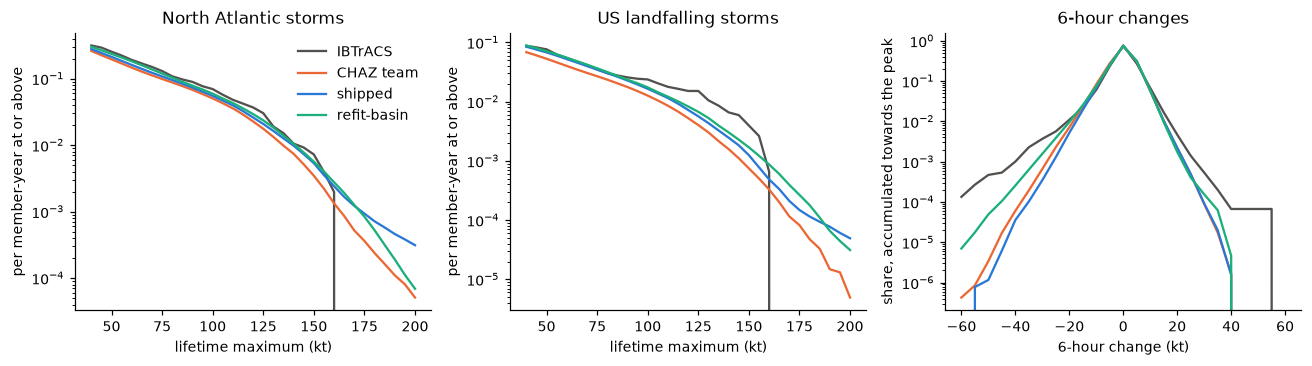

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.4))
shown = ['IBTrACS', 'CHAZ team', 'shipped', 'refit-basin']
for ax, (prefix, total, title) in zip(
    axes[:2],
    (('lmi >=', 'na', 'North Atlantic storms'), ('lf lmi >=', 'us', 'US landfalling storms')),
):
    for name in shown:
        sums = tables[name].loc[list(YEARS)].sum()
        per_year = report._columns(sums, prefix, report.LMI) / sums['members'] / len(YEARS)
        ax.semilogy(report.LMI, per_year, color=COLORS[name], label=name)
    ax.set(xlabel='lifetime maximum (kt)', ylabel='per member-year at or above', title=title)
for name in shown:
    sums = tables[name].loc[list(YEARS)].sum()
    histogram = report._columns(sums, 'dv', report.DV)
    curve = report.double_sided(histogram, int(np.argmax(histogram))) / histogram.sum()
    axes[2].semilogy(report.DV, curve, color=COLORS[name], label=name)
axes[2].set(
    xlabel='6-hour change (kt)',
    ylabel='share, accumulated towards the peak',
    title='6-hour changes',
)
axes[0].legend(frameon=False)
fig.tight_layout()

Every CHAZ set scores close to 1 on the basin intensity histogram (0.98–1.00 on D′ and r²), the
6-hour intensity change (K′ 1.00) and the annual cycle (0.94–0.98). Plain refit is the exception on
the basin histogram, with K′ 0.90 and χ²′ 0.91. The sets differ at landfall. On the lifetime maxima
of US landfalling storms, K′ is 0.77 for the shipped run and 0.79 for refit-basin, against 0.69 for
plain refit and 0.68 for the CHAZ team's set, and χ²′ follows (0.72, 0.75, 0.62, 0.58). On the
wind at landfall K′ is 0.58 for the shipped run and refit-basin and 0.35–0.38 for the other two.
Against IBTrACS in CHAZ's 12-hourly form most landfall scores rise: the shipped run's K′ to 0.84 on
the landfall lifetime maxima and 0.79 on the wind at landfall. Rk′ is 0.94 for the CHAZ team's set
and 1.06–1.09 for our runs (0.97 and 1.09–1.12 against the 12-hourly form), within the range from
0.75 to 1.25 that Emanuel counts as good. In the ln(1 + count) form the change before landfall has
no bin above the cutoff in both series, so only r² is defined (0.92–0.96).

## Summary

Our implementation of Emanuel (2025)'s tests reproduces John et al.'s RAFT scores for the annual
cycle and some of the basin-scale scores, not their landfall scores; without their code and coastal
gates we cannot say which readings differ. On these metrics the shipped run and refit-basin score
alike: close to observed for the basin as a whole, and lower at landfall, where they score above
plain refit and the CHAZ team's set on the intensity of landfalling storms (K′ 0.58 for both on the
wind at landfall). The metrics scale the storm count away, so we use them as a check;
[intensity.ipynb](intensity.ipynb) compares the setups.

Open: John et al.'s coastal gates and test code, which would show where our readings differ from
theirs.